## Lab 4
### Working with Real Data
#### 10/27 
#### Will Stelter
#### 10/29 Ran into an issue - data or code seems to have gotten screwed up since Tuesday. Plots no longer show what they showed! Diagnosis and attempts to fix at bottom of notebook
#### 10/29 Proceeding with lab using original data file downloaded off of canvas and uploaded to JupyterHub. For my own curiousity, I'm leaving the diagnostic steps I used ChatGPT for down at the bottom for now - they were interesting and I'd like to study them later. In fact, I'd be glad to discuss them 

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [2]:
# load file in read mode
hf = h5py.File('/home/jovyan/Stelter434/gammaray_lab4.h5', 'r')
# list names of data sets
hf.keys()
# import selected data set from file into an array
data = np.array(hf.get('data'))
# check data import went well 
# check dimensions of arrays
np.shape(data)
data[:,0]

# data takes form time (in gps seconds), Solar phase (deg), Earth longitude (deg), and gamma-ray counts

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [3]:
# close file - sever active connection ?
hf.close()
# Should this line be ni the same line as the above bits? I'm guessing that it doesn't actually matter

### Problemo
#### In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

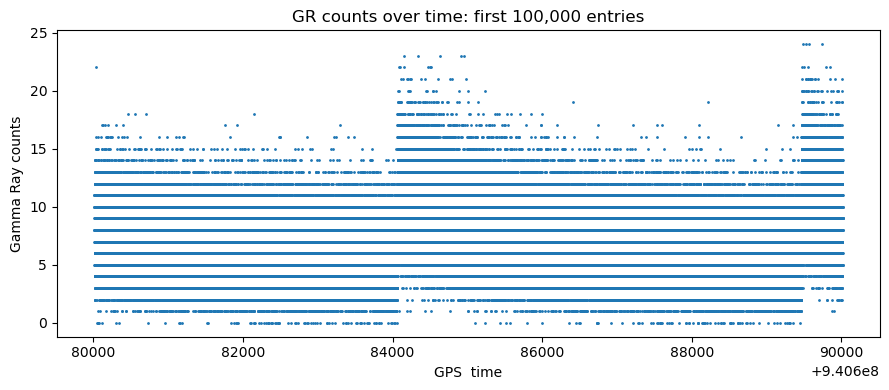

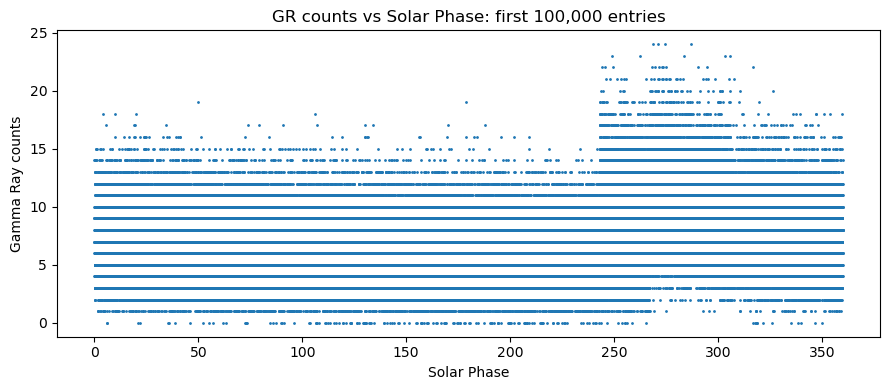

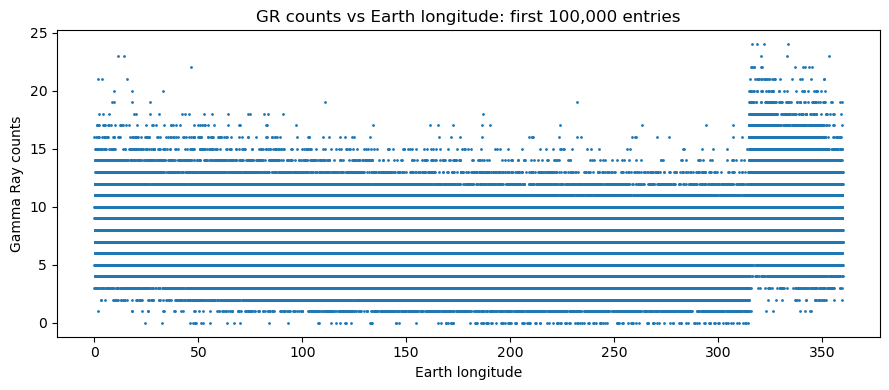

gamma ray incident rate seems to jump regularly - sunrise from satellite's POV?


In [4]:
# Examine the data 
# Goal: plot gamma ray counts vs time, solar phase, and Earth longitude 

# gr count vs time
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[0][:100000], data[3][:100000] , s=1)

plt.xlabel("GPS  time")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts over time: first 100,000 entries")
plt.tight_layout()
plt.show()


# gr count vs solar phase
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[1][:100000], data[3][:100000] , s=1)

plt.xlabel("Solar Phase")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts vs Solar Phase: first 100,000 entries")
plt.tight_layout()
plt.show()

# GR count vs Earth longitude
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(data[2][:100000], data[3][:100000] , s=1)

plt.xlabel("Earth longitude")
plt.ylabel("Gamma Ray counts")
plt.title("GR counts vs Earth longitude: first 100,000 entries")
plt.tight_layout()
plt.show()

print("gamma ray incident rate seems to jump regularly - sunrise from satellite's POV?")

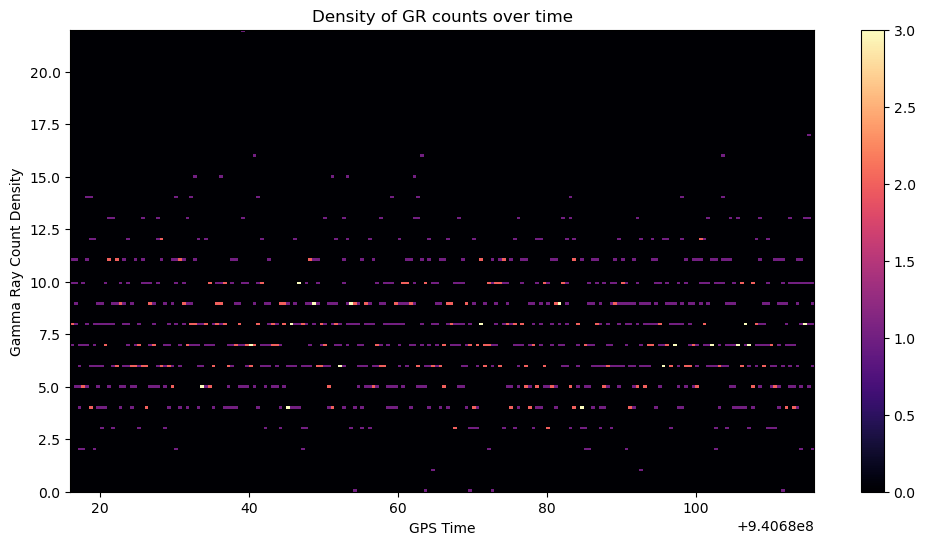

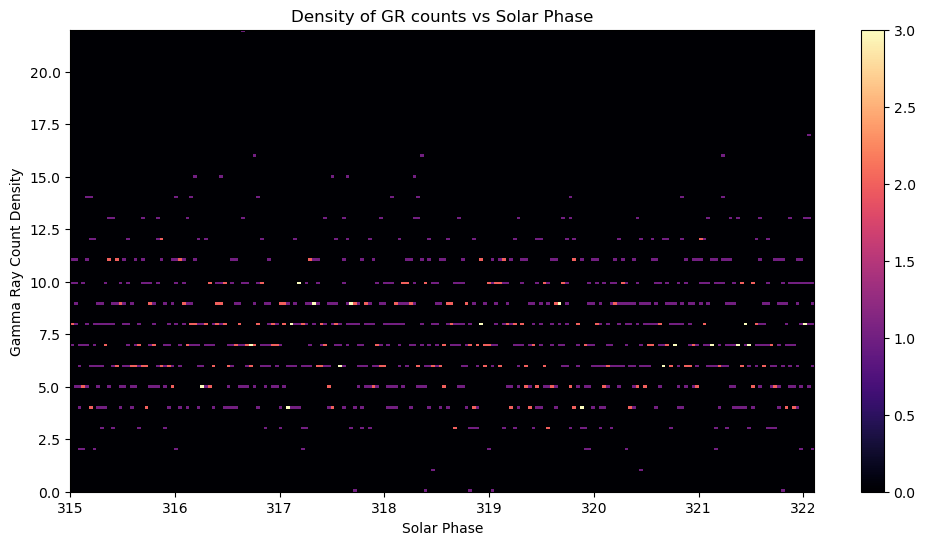

In [5]:
# 2D histogram Gamma Ray Count Density vs GPS Time

plt.figure(figsize=(12,6))

plt.hist2d(data[0][:1000], data[3][:1000], bins=200, cmap="magma");

plt.xlabel("GPS Time")
plt.ylabel("Gamma Ray Count Density")
plt.title("Density of GR counts over time")

plt.colorbar()
plt.show()

# 2D histogram Gamma Ray Count Density vs Solar Phase

plt.figure(figsize=(12,6))

plt.hist2d(data[1][:1000], data[3][:1000], bins=200, cmap="magma");

plt.xlabel("Solar Phase")
plt.ylabel("Gamma Ray Count Density")
plt.title("Density of GR counts vs Solar Phase")

plt.colorbar()
plt.show()



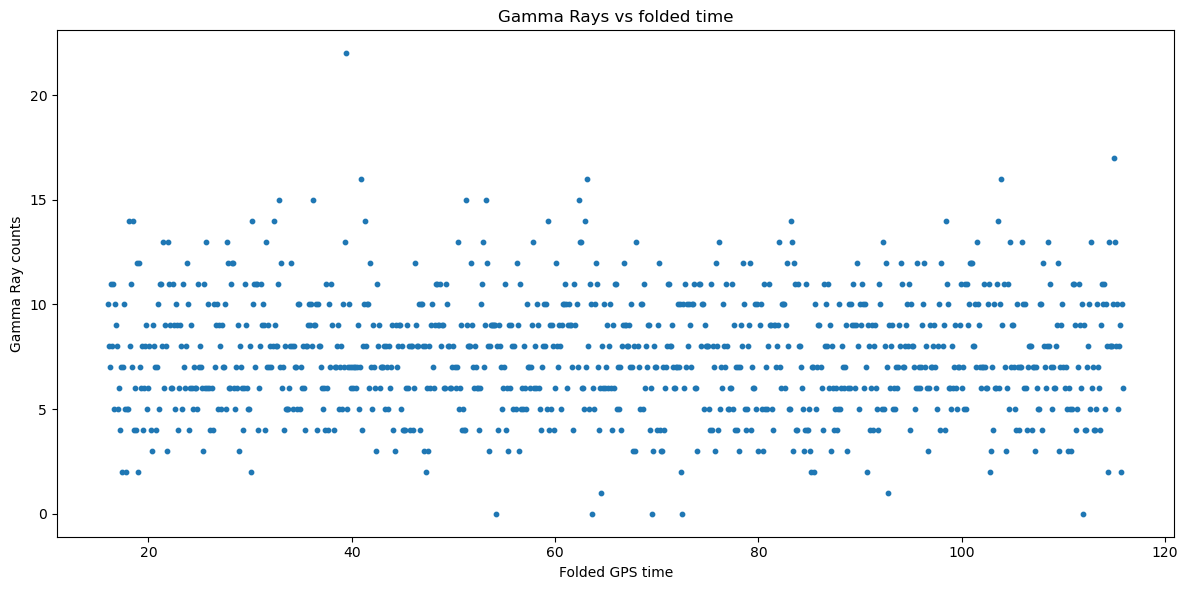

In [6]:
# fold GPS time as a periodic function 
# 90 minute orbit - data entry every 100 milliseconds -> 54,000 entries per orbit

fiveorbits = 54000
foldtime = np.asarray(data[0] % (fiveorbits))

# plot first 1000 points of folded time and GR counts
plt.figure(figsize=(12, 6))
plt.scatter(foldtime[:1000], data[3][:1000], s=10)
plt.xlabel("Folded GPS time")
plt.ylabel("Gamma Ray counts")
plt.title("Gamma Rays vs folded time")
plt.tight_layout()
plt.show()

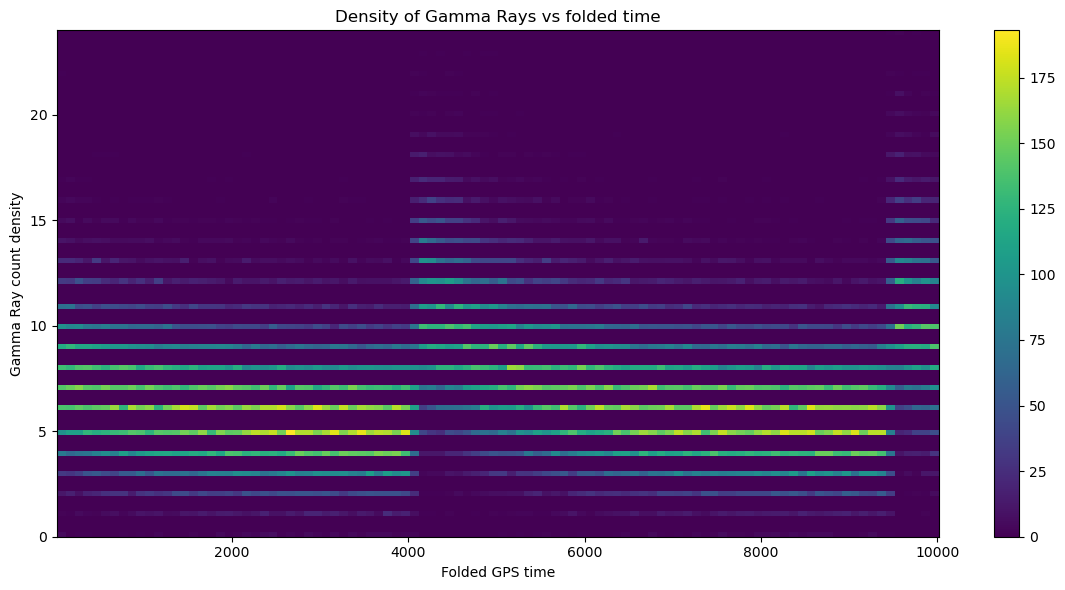

In [7]:
# density of counts vs folded time
plt.figure(figsize=(12, 6))
plt.hist2d(foldtime[:100000], data[3][:100000], bins=100, cmap='viridis')
plt.xlabel("Folded GPS time")
plt.ylabel("Gamma Ray count density")
plt.title("Density of Gamma Rays vs folded time")
plt.tight_layout()
plt.colorbar()
plt.show()


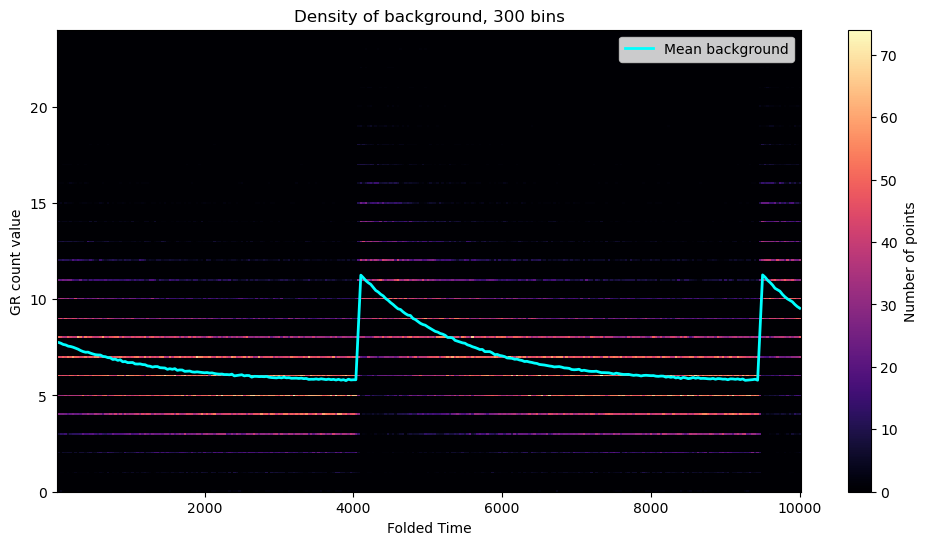

In [8]:
#3c
# create the 2D histogram
fig, ax = plt.subplots(figsize=(12, 6))

# hist, xedges, yedges, image - objects returned when calling ax.hist2d()
# writing them out as such is multiple assignment/ unpacking
hist, xedges, yedges, image = ax.hist2d(foldtime[:100000], data[3][:100000], bins=300, cmap="magma")

# calculate the mean background value in each folded-time bin
# stats.binned_statistic() returns 3 objects,
mean_bkgd, bin_edges, binnumber = stats.binned_statistic(foldtime, data[3], statistic="mean", bins=xedges)

# find the center of each folded-time bin 
# ( Final minus initial ) / 2
ft_centers = (xedges[:-1] + xedges[1:]) / 2

# overlay the mean background values as a line
ax.plot(ft_centers, mean_bkgd, color="cyan", linewidth=2, label="Mean background")

# labels for plot
ax.set_xlabel("Folded Time")
ax.set_ylabel("GR count value")
ax.set_title("Density of background, 300 bins")
ax.legend()

# color bar
fig.colorbar(image, ax=ax, label="Number of points")

plt.show()

### 1) discussion
#### The detector regularly sees a large jump in Gamma Ray counts. We believe this is because of Sol being regularly de-eclipsed by the Earth!
#### That is, the detector sees fewer Gamma Rays while on the night side of Earth. When it comes around and sees Sol again, a large jump in GR detection rate appears.

### 2) discussion 
#### There's a Poissonian distribution of  discrete counts that also exhibits an exponential decay behavior.
#### Gamma Ray detection is inherently Poissonian (not sure how to explain this more thoroughly - I don't feel confident that I can explain the meaning of this statement. I feel like I'm presenting a tautology - "It Is, because It Is") 
#### The exponential decay appears to follow the satellite's orbit cycle. Sunrise from satellite's POV -> influx of gamma rays from Sol

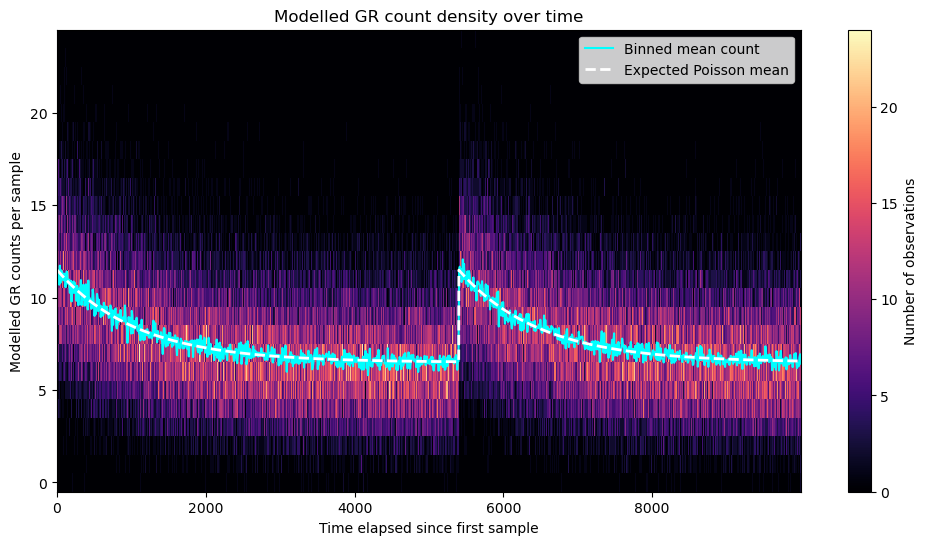

Number of cycles spanned: 1.851833333328918


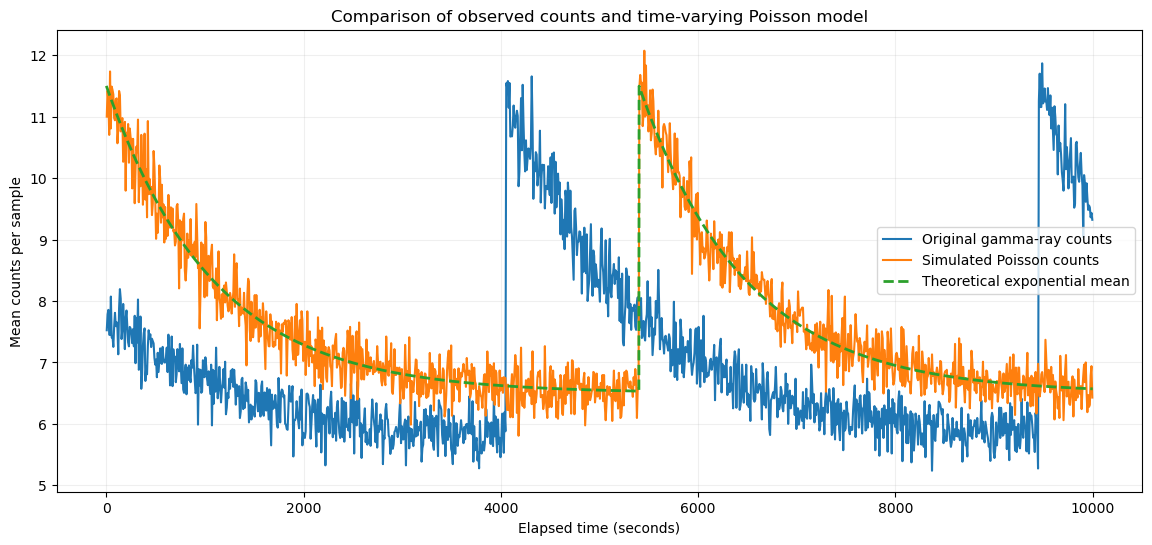

In [11]:
# number of samples to model
n = 100000

# extract the GPS timestamps
time_gps = np.asarray(data[0][:n])

# convert GPS time into elapsed time since the first sample
elapsed = time_gps - time_gps[0]

# parameters of the exponential time variance function
amp = 5.0       # amplitude, difference between low and high means of 11.5 and 6.5 ish
per = 5400     # period of repetition - entries per 90min orbit ?
k2 = amp / per       # exponential decay constant as function of period
c = 6.5       # positive vertical offset - low mean value of 6.5

# fold GPS time into repeating cycle
phase = elapsed % per

# calculate expected distribution count at each time
expected_mean = amp * np.exp(-k2 * phase) + c

# generate random Poisson counts using expected mean - with a repeatable seed 
rng = np.random.default_rng(42)
model = rng.poisson(lam=expected_mean)


# create the 2D histogram - object oriented
fig, ax = plt.subplots(figsize=(12, 6))

# set 1200 horizontal bins and one bin for each integer count
x_bins = np.linspace(0, elapsed[-1], 1201)
y_bins = np.arange(-0.5, model.max() + 1.5, 1)

hist, xedges, yedges, image = ax.hist2d(elapsed, model, bins=[x_bins, y_bins], cmap="magma")

# calculate the mean background value in each folded-time bin
mean_bkgd, bin_edges, binnumber = stats.binned_statistic(elapsed, model, statistic="mean", bins=xedges)

# find the center of each folded-time bin 
# ( Final minus initial ) / 2
t_centers = (xedges[:-1] + xedges[1:]) / 2

#plot biinned average of the simulated counts
ax.plot(t_centers, mean_bkgd, color="cyan", linewidth=1.5, label="Binned mean count")

# calculate a smooth version of the expected repeating mean
smooth_time = np.linspace(0, elapsed[-1], 5000)
smooth_phase = smooth_time % per
smooth_mean = amp * np.exp(-k2 * smooth_phase) + c

# Overlay the theoretical mean
ax.plot(smooth_time, smooth_mean, color="white", linestyle="--", linewidth=2, label="Expected Poisson mean")

# labels for plot
ax.set_xlabel("Time elapsed since first sample")
ax.set_ylabel("Modelled GR counts per sample")
ax.set_title("Modelled GR count density over time")
ax.legend()

# color bar
fig.colorbar(image, ax=ax, label="Number of observations")

plt.show()
print("Number of cycles spanned:", elapsed[-1] / per)

# extract the original gamma-ray counts from the data
observed = np.asarray(data[3][:n], dtype=float)

# calculate the mean original count in each time bin
observed_mean, bin_edges, binnumber = stats.binned_statistic(elapsed, observed, statistic="mean", bins=x_bins)

# calculate the mean simulated count in each time bin
model_mean, bin_edges, binnumber = stats.binned_statistic(elapsed, model, statistic="mean", bins=x_bins)

# calculate the theoretical mean curve
smooth_time = np.linspace(0, elapsed.max(), 5000)
smooth_phase = smooth_time % per
smooth_mean = amp * np.exp(-k2 * smooth_phase) + c

# plot the comparison
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(t_centers, observed_mean, label="Original gamma-ray counts", linewidth=1.5)

ax.plot(t_centers, model_mean, label="Simulated Poisson counts", linewidth=1.5)

ax.plot(smooth_time, smooth_mean, "--", label="Theoretical exponential mean", linewidth=2)

ax.set_xlabel("Elapsed time (seconds)")
ax.set_ylabel("Mean counts per sample")
ax.set_title("Comparison of observed counts and time-varying Poisson model")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

### 3) How well does this model the actual data?
#### The form is right. It's out of phase and its range is ever so slightly high. 

### 4) What is the 5-sigma detection threshold for a .1 second GRB?
#### In order to determine the sigma value for a detection, one could apply the inverse survival function to the data distribution. The inverse survival function calls for a probability - this probability falls out of the standard normal

The percentage chance of a 5 sigma detection is: 2.866515718791933e-07


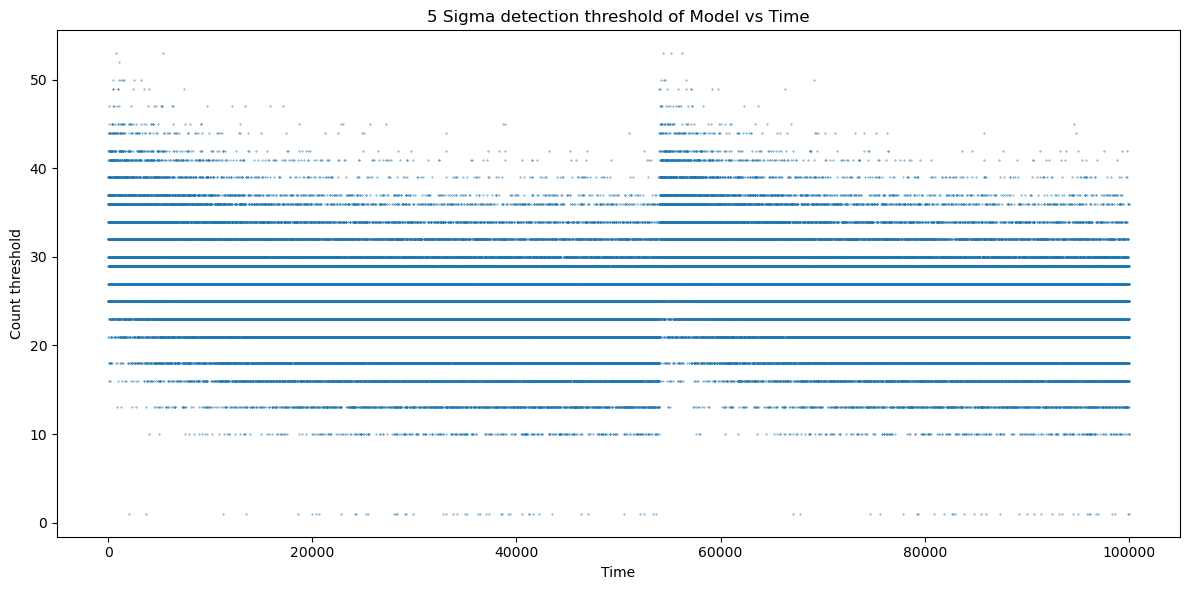

In [23]:
# apply survival function to standard normal to find the probability of a 5 sigma detection
five_sigma_prob = stats.norm.sf(5)
print('The percentage chance of a 5 sigma detection is:', five_sigma_prob)


#calculate the 5-sigma threshold for every entry in array 
# note the +1! 
five_sigma_threshold = stats.poisson.isf(five_sigma_prob, model) + 1

# plot 5 sigma detection threshold for the model
plt.figure(figsize=(12, 6))
plt.scatter(np.linspace(start=0, stop=len(five_sigma_threshold), num=len(five_sigma_threshold)), five_sigma_threshold, s=.1)
plt.xlabel("Time")
plt.ylabel("Count threshold")
plt.title("5 Sigma detection threshold of Model vs Time")
plt.tight_layout()
plt.show()

## 5) What is causing this behaviour?
#### Reiterating previous hypothesis: While the satellite's view of Sol is blocked by Earth, solar gamma rays do not reach the detector. When the satellite's orbit takes it to a 'sunrise' it begins seeing those solar rays again.

## 10/29 Data file problem work below
## Something happened between lab on Tuesday and 12 pm on Thursday. My plots no longer make sense. I'm trying to diagnose what went wrong. I've never done this before, so I'm bouncing ideas off of ChatGPT. Most of the code  below is copy-pasted from there! Hope that's ok


In [ ]:

# Check the dimensions of the array
print("Array shape:", data.shape)

# Check whether all values are finite numbers
print("All values finite:", np.isfinite(data).all())

# Print the minimum, maximum, mean, and standard deviation of each row
for i in range(4):
    print(
        f"Row {i}:",
        f"min = {np.min(data[i])},",
        f"max = {np.max(data[i])},",
        f"mean = {np.mean(data[i])},",
        f"std = {np.std(data[i])}"
    )


### Did rows 2, 3 and 4 (Soalr Phase, Earth longitude and Gamma Ray Count) somehow get mixed up? Longitude value shouldn't have same order-of-magnitude as gamma ray counts. Same for Solar Phase. Also max gamma ray counts in the hundreds of millions??? Nearly a billion? ??
### Seems like there's a problem with either: A) the data file itself, or B) the process of loading the data into the "data" array 

In [ ]:
import os
from datetime import datetime

# Specify the exact file used by your notebook
path = '/home/jovyan/Shared/gammaray_lab4.h5'

# Check the file's location, size, and last-modified time
print("File path:", os.path.realpath(path))
print("File size:", os.path.getsize(path), "bytes")
print(
    "Last modified:",
    datetime.fromtimestamp(os.path.getmtime(path))
)

# Reopen the file and inspect its contents
with h5py.File(path, 'r') as hf:

    # List the available datasets
    print("\nAvailable datasets:", list(hf.keys()))

    # Inspect the specific dataset used in your analysis
    ds = hf['data']

    print("Dataset shape:", ds.shape)
    print("Dataset data type:", ds.dtype)
    print("Dataset attributes:", dict(ds.attrs))

    # Display the first 12 observations from all four rows
    print("\nFirst 12 columns:")
    print(ds[:, :12])

    # Display another small sample
    print("\nColumns 1000 through 1011:")
    print(ds[:, 1000:1012])

    # Inspect the end of the dataset
    print("\nLast 12 columns:")
    print(ds[:, -12:])

### Shared data file last modified yesterday evening (10/28 just before 11pm)
### Suspicion: the data file changed between lab on Tuesday and Thursday
### Not by me - the supplied code loaded the file in read only mode

In [ ]:
# Examine the exact samples used in your histograms
for i in range(4):
    values = data[i, :1000]

    print(
        f"Row {i}:",
        f"min = {values.min()},",
        f"max = {values.max()},",
        f"mean = {values.mean()},",
        f"std = {values.std()}"
    )

# Check whether the angle rows contain values outside 0 to 360 degrees
for i in [1, 2]:
    bad_indices = np.flatnonzero(
        (data[i, :1000] < 0) | (data[i, :1000] >= 360)
    )

    print(f"\nRow {i}:")
    print("Number of out-of-range angles:", len(bad_indices))
    print("First 10 suspicious indices:", bad_indices[:10])
    print("Their values:", data[i, bad_indices[:10]])

# Look for timestamp-sized values in the count row
large_indices = np.flatnonzero(data[3, :1000] > 1_000_000)

print("\nRow 3:")
print("Number of values above one million:", len(large_indices))
print("Their first indices:", large_indices[:10])
print("Their values:", data[3, large_indices[:10]])

In [ ]:
# Timestamp-sized values are much larger than ordinary angles.
threshold = 1_000_000

for i in range(4):
    row = data[i]

    # True where a value is larger than the threshold
    is_time_sized = row > threshold

    # Find the indices where this condition changes
    boundaries = np.flatnonzero(
        is_time_sized[1:] != is_time_sized[:-1]
    ) + 1

    print(f"\nRow {i}")
    print("Number of transitions:", len(boundaries))
    print("First transition indices:", boundaries[:10])

    # Print the values immediately around the first few transitions
    for k in boundaries[:5]:
        start = max(0, k - 2)
        stop = min(len(row), k + 3)
        print(f"Values near index {k}:", row[start:stop])

# Sample positions spread across the entire dataset
sample_indices = np.linspace(
    0, data.shape[1] - 1, 9, dtype=int
)

print("\nSample indices across the full dataset:")
print(sample_indices)

for i in range(4):
    print(f"Row {i}:", data[i, sample_indices])

In [ ]:
path = '/home/jovyan/Shared/gammaray_lab4.h5'

# Inspect how the HDF5 dataset is stored
with h5py.File(path, 'r') as hf:
    ds = hf['data']

    print("Shape:", ds.shape)
    print("Data type:", ds.dtype)
    print("Chunk shape:", ds.chunks)
    print("Compression:", ds.compression)
    print("Compression options:", ds.compression_opts)
    print("Shuffle filter:", ds.shuffle)
    print("Fletcher32 checksum:", ds.fletcher32)

# Check whether the GPS time row moves backward
time_differences = np.diff(data[0])

backward_jumps = np.flatnonzero(time_differences < 0)

print("\nGPS time diagnostics")
print("Number of backward steps:", len(backward_jumps))
print("Smallest time step:", np.min(time_differences))
print("Largest time step:", np.max(time_differences))

# Show the first few backward jumps
for i in backward_jumps[:10]:
    print(
        f"Index {i} -> {i + 1}:",
        data[0, i], "->", data[0, i + 1],
        "| Difference:", time_differences[i]
    )

## The data file's GPS time makes no sense. The values go backwards 66 times- once, by a value of over 1 million! Given the sampling rate of 100ms, this is a backwards step of over 100,000 seconds.
## ChatGPT noted the beginning GPS timestamp and predicted the ending timestamp given the .1 second sampling rate. The ending timestamp value appears in the Solar Phase row, not at the end of the GPS time row.
## Clearly, the data file changed. Why?